# Calibrating Fisher forecasts of the core size against inference

How well does a Fisher forecast predict the uncertainty on the CIS core size $x_c$ that full Bayesian inference finds? This notebook compares the two for the LIGO mass scan of the paper: a lens with $x_c = 0.02$ at $y = 0.3$, for $M_{Lz} = 3$ to $1000\,M_\odot$, with the 30+30 $M_\odot$ benchmark source at 500 Mpc.

1. Read the width of the $x_c$ posterior from the shipped mass-scan samples.
2. Read the Fisher covariance of $(\ln M_{Lz}, y, x_c)$ at the same points, and restrict the Fisher Gaussian to the prior used in inference.
3. Compare the two (the paper's calibration figure).
4. Translate the same posteriors into the SIDM cross section, marginalizing over the lens redshift as in Tambalo et al. (2023, T23), and show how the bound tightens with lens mass.
5. Compare these limits with other probes of SIDM (the paper's two SIDM figures).

The Fisher grid ships in `data/core_fisher_LIGO_CIS.npz`. To recompute it, run `python scripts/1_fisher/core_size_fisher.py LIGO` (about 15 minutes on 112 cores, `slurm/core_size_fisher.sh`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths, posteriors

## 1. Posterior width of $x_c$

The mass-scan runs sample $x_c$ (stored as `lp`) with a flat prior on $[0, 1]$. Where the data carry no information on the core, the posterior width approaches the width of that prior, $1/\sqrt{12} \approx 0.29$.

In [2]:
MASSES = [3, 10, 30, 100, 300, 1000]
XC_TRUE, Y_TRUE = 0.02, 0.3
pe_std = {m: posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))[0]['lp'].std() for m in MASSES}
pd.Series(pe_std, name='posterior std of x_c').rename_axis('M_Lz').to_frame().T

M_Lz,3,10,30,100,300,1000
posterior std of x_c,0.287802,0.277873,0.200071,0.125345,0.031577,0.011368


## 2. The Fisher forecast, restricted to the prior

The Fisher grid holds, at each $(x_c, M_{Lz}, y)$, the covariance of $(\ln M_{Lz}, y, x_c)$ after marginalizing over the distance, the phase and the arrival time, as in inference. Where the data are weak this Gaussian is much wider than the prior, and part of it lies at unphysical values such as $x_c < 0$. Comparing its raw $\sigma(x_c)$ with the posterior would count that region.

The inference prior is flat in $(\ln M_{Lz}, y, x_c)$: log-uniform $M_{Lz} \in [0.1, 2000]\,M_\odot$, $y \in [0.1, 5]$, $x_c \in [0, 1]$. So the Fisher approximation of the posterior is the Fisher Gaussian truncated to that box. We draw from the Gaussian, keep the draws inside the box, and take the standard deviation of $x_c$. (The prior also excludes a narrow band around the caustic, which we do not remove here.)

In [3]:
grid = np.load(paths.CORE_FISHER_GRID)
LNM_BOX, Y_BOX, XC_BOX = (np.log(0.1), np.log(2000.0)), (0.1, 5.0), (0.0, 1.0)
Z = np.random.default_rng(1).standard_normal((400000, 3))      # the same normal draws for every point


def truncated_std(cov, truth):
    # std of x_c for the Gaussian N(truth, cov) in (ln M_Lz, y, x_c), restricted to the prior box
    w, V = np.linalg.eigh(cov)
    s = np.asarray(truth) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
    inside = ((s[:, 0] >= LNM_BOX[0]) & (s[:, 0] <= LNM_BOX[1]) & (s[:, 1] >= Y_BOX[0]) & (s[:, 1] <= Y_BOX[1])
              & (s[:, 2] >= XC_BOX[0]) & (s[:, 2] <= XC_BOX[1]))
    return s[inside, 2].std()


i, k = list(grid['x_c']).index(XC_TRUE), list(grid['y']).index(Y_TRUE)
M_grid = grid['M_Lz']
raw = grid['sigma_xc_t'][i, :, k]                                        # with t_c, as in inference
trunc = np.array([truncated_std(grid['cov_t'][i, j, k], (np.log(M), Y_TRUE, XC_TRUE)) for j, M in enumerate(M_grid)])

# the PE masses fall between grid masses: interpolate in log M_Lz
interp = lambda v, m: 10 ** np.interp(np.log10(m), np.log10(M_grid), np.log10(v))
CAL = pd.DataFrame({'M_Lz': MASSES, 'posterior std': [pe_std[m] for m in MASSES],
                    'Fisher sigma (no prior)': [interp(raw, m) for m in MASSES],
                    'Fisher std (truncated to prior)': [interp(trunc, m) for m in MASSES]})
CAL['posterior / Fisher (truncated)'] = CAL['posterior std'] / CAL['Fisher std (truncated to prior)']
CAL.round(3)

,M_Lz,posterior std,Fisher sigma (no prior),Fisher std (truncated to prior),posterior / Fisher (truncated)
0,3,0.288,24.091,0.296,0.972
1,10,0.278,5.842,0.287,0.967
2,30,0.200,1.566,0.269,0.745
3,100,0.125,0.473,0.159,0.788
4,300,0.032,0.131,0.072,0.441
5,1000,0.011,0.014,0.012,0.934


Without the prior, the Fisher $\sigma(x_c)$ exceeds the width of the prior by up to two orders of magnitude at low lens mass, where it only says that the data carry no information. Truncated to the prior, it reproduces the posterior there. At $M_{Lz} = 1000\,M_\odot$, where the data dominate, the two methods agree to 10%. In between ($M_{Lz} = 30$ to $300\,M_\odot$) the Fisher forecast is conservative by a factor of up to about two, because the likelihood there is far from Gaussian.

## 3. The calibration figure

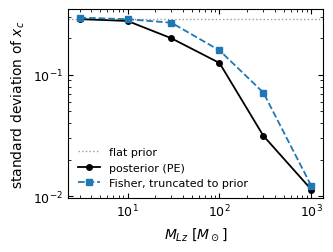

In [4]:
paths.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 8, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    ax.axhline(1 / np.sqrt(12), color='0.6', ls=':', lw=1, label='flat prior')
    ax.loglog(CAL['M_Lz'], CAL['posterior std'], 'o-', color='k', ms=4, lw=1.3, label='posterior (PE)')
    ax.loglog(CAL['M_Lz'], CAL['Fisher std (truncated to prior)'], 's--', color='tab:blue', ms=4, lw=1.3,
              label='Fisher, truncated to prior')
    ax.set(xlabel=r'$M_{Lz}\ [M_\odot]$', ylabel=r'standard deviation of $x_c$')
    ax.legend(frameon=False, loc='lower left')
    fig.tight_layout()
    for ext in ('pdf', 'png'):
        fig.savefig(paths.FIGURES_DIR / f'calibration_width.{ext}', dpi=300, bbox_inches='tight')
    plt.show()

## 4. SIDM cross section along the mass scan

Reading the CIS core as an SIDM core, the core-formation condition $\langle\sigma v\rangle\,\rho(r_c)\,t_{\rm age}/m \simeq 1$ on the CIS profile gives the cross section per unit mass,
$$\frac{\sigma}{m} = \frac{4\pi G\,(x_c\,\xi_0)^2}{\sigma_v^2\,\langle v\rangle\,t_{\rm age}},\qquad \sigma_v^2 = \frac{\xi_0\,c^2}{4\pi D},\qquad \langle v\rangle = \frac{4\sigma_v}{\sqrt{\pi}},$$
where $\xi_0$ is the Einstein radius, $D = D_L D_{LS}/D_S$, and $t_{\rm age} = 5$ Gyr.

The conversion needs the lens redshift, which a single event does not measure. As in T23 (their Eq. 69), we marginalize over it with
$$\frac{dP}{dz_L} \propto \xi_0^2\,\frac{(1+z_L)^2}{H(z_L)}\left|\frac{\partial M_{Lz}}{\partial M_{\rm vir}}\right|^{-1}\frac{dn}{dM_{\rm vir}}\bigl(M_{\rm vir}(M_{Lz}, z_L), z_L\bigr),$$
the lensing cross section times the comoving volume and the number density of halos of the mass that gives the measured $M_{Lz}$ at that redshift. $M_{\rm vir}(M_{Lz}, z_L)$ is T23's SIS relation and $dn/dM_{\rm vir}$ the Tinker et al. (2008) mass function from Colossus, in the flat cosmology used throughout ($H_0 = 70$ km/s/Mpc, $\Omega_m = 0.3$).

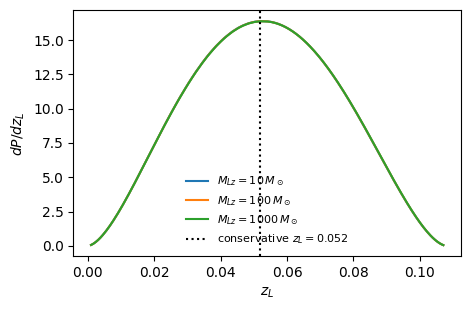

In [5]:
from colossus.cosmology import cosmology
from colossus.lss import mass_function
from scipy.constants import G as G_SI, c as C_SI
from infer_with_fiona import dm_conversions as D

MSUN, GPC_M, GYR_S = 1.98847e30, 3.0856775814913673e25, 3.15576e16
H0, OM = 70.0, 0.3
cosmo = cosmology.setCosmology('paper_flat70', {'flat': True, 'H0': H0, 'Om0': OM, 'Ob0': 0.0486,
                                                'sigma8': 0.8159, 'ns': 0.9667})
z_S = D.z_source(500.0)                                   # the injected source, d_L = 500 Mpc
z_L_cons = D.zL_pessimistic(z_S)                          # T23's conservative choice, for reference
ZL = np.linspace(1e-3, z_S - 1e-3, 300)
DEFF = np.array([D.d_eff_Gpc(float(z), z_S) for z in ZL])  # d_eff(z_L) [Gpc]


def m_vir(mlz, zl, deff):
    # T23's SIS relation between the lens mass and the virial mass (h = 0.7)
    return (mlz * (6.5e17 * deff ** -3) ** (1 / 3) / (2 * (1 + zl) ** 2)) ** 0.75


def p_zL(mlz):
    # T23 Eq. (69) on the z_L grid, normalized
    mv = m_vir(mlz, ZL, DEFF)
    dndlnM = np.array([mass_function.massFunction(m * cosmo.h, z, mdef='200c', model='tinker08', q_out='dndlnM')
                       for m, z in zip(mv, ZL)])
    xi0_sq = 4 * G_SI * mlz * MSUN * DEFF * GPC_M / C_SI ** 2
    p = xi0_sq * (1 + ZL) ** 2 / np.sqrt(OM * (1 + ZL) ** 3 + 1 - OM) * 0.75 * mv / mlz * dndlnM * cosmo.h ** 3 / mv
    return p / np.trapezoid(p, ZL)


LOGM = np.linspace(-1.2, np.log10(2000) + 0.6, 70)        # tabulate the CDF of z_L against M_Lz
CDF = []
for lm in LOGM:
    p = p_zL(10 ** lm)
    cdf = np.concatenate([[0], np.cumsum(0.5 * (p[1:] + p[:-1]) * np.diff(ZL))])
    CDF.append(cdf / cdf[-1])
CDF = np.array(CDF)
rng = np.random.default_rng(20261020)


def draw_zL(mlz):
    # one z_L per sample, from P(z_L | M_Lz) at the nearest tabulated mass
    i = np.clip(np.round(np.interp(np.log10(mlz), LOGM, np.arange(len(LOGM)))).astype(int), 0, len(LOGM) - 1)
    return np.array([np.interp(u, CDF[ii], ZL) for u, ii in zip(rng.uniform(size=len(mlz)), i)])


def v_and_sigma_over_m(xc, mlz, zl, t_age_gyr=5.0):
    # <v> [km/s] and sigma/m [cm^2/g] from the core-formation condition on the CIS profile
    deff = np.interp(zl, ZL, DEFF) * GPC_M
    xi0 = np.sqrt(4 * G_SI * mlz * MSUN * deff / C_SI ** 2)
    sv = np.sqrt(xi0 * C_SI ** 2 / (4 * np.pi * (1 + zl) * deff))
    v = 4 / np.sqrt(np.pi) * sv
    return v / 1e3, 4 * np.pi * G_SI * (np.asarray(xc) * xi0) ** 2 / (sv ** 2 * v * t_age_gyr * GYR_S) * 10.0


fig, ax = plt.subplots(figsize=(5, 3.2))
for m in [10, 100, 1000]:
    ax.plot(ZL, p_zL(m), label=rf'$M_{{Lz}}={m}\,M_\odot$')
ax.axvline(z_L_cons, color='k', ls=':', label=f'conservative $z_L={z_L_cons:.3f}$')
ax.set(xlabel='$z_L$', ylabel=r'$dP/dz_L$')
ax.legend(fontsize=8, frameon=False)
plt.show()

For our nearby source ($z_S = 0.108$) and these light halos, the mass function hardly changes between $z_L = 0$ and $0.1$, so $P(z_L)$ follows the lensing cross section $\propto \xi_0^2 \propto d_{\rm eff}$. It is the same for every $M_{Lz}$ and peaks at T23's conservative choice, the $z_L$ that maximizes $(1+z_L)\,d_{\rm eff}$.

Each posterior sample of $(M_{Lz}, x_c)$ gets its own $z_L$ drawn from $P(z_L \mid M_{Lz})$. At $M_{Lz} = 3$ and $10\,M_\odot$ the $x_c$ posterior fills its prior, so only $M_{Lz} \ge 30\,M_\odot$ are shown. The injected value is shown at the median over $P(z_L)$.

In [6]:
SCAN = [30, 100, 300, 1000]
SIG, INJ, VEL = {}, {}, {}
rows = []
for m in SCAN:
    s, _ = posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))
    mlz = np.asarray(s['MLz'])
    SIG[m] = v_and_sigma_over_m(np.maximum(s['lp'], 1e-6), mlz, draw_zL(mlz))[1]
    v_t, s_t = v_and_sigma_over_m(XC_TRUE, float(m), draw_zL(np.full(20000, float(m))))
    INJ[m], VEL[m] = np.median(s_t), np.median(v_t)
    rows.append({'M_Lz': m, '<v> [km/s]': VEL[m], 'x_c 95% UL': np.percentile(s['lp'], 95),
                 'sigma/m 95% UL [cm2/g]': np.percentile(SIG[m], 95), 'sigma/m injected [cm2/g]': INJ[m]})
pd.DataFrame(rows).set_index('M_Lz').style.format('{:.3g}')

,[km/s],x_c 95% UL,sigma/m 95% UL [cm2/g],sigma/m injected [cm2/g]
M_Lz,,,,
30,2.93,0.58,2.58e-06,2.18e-09
100,3.96,0.428,1.42e-06,2.94e-09
300,5.22,0.114,1.4e-07,3.87e-09
1000,7.05,0.0393,1.94e-08,5.2e-09


The $x_c$ upper limit falls from 0.58 at $M_{Lz} = 30\,M_\odot$ to 0.04 at $1000\,M_\odot$, so the bound on $\sigma/m$ tightens by about two orders of magnitude, although heavier lenses have larger physical cores ($\xi_0 \propto M_{Lz}^{1/2}$) and faster halos ($\langle v\rangle \propto M_{Lz}^{1/4}$). At $1000\,M_\odot$ the bound approaches the injected value.

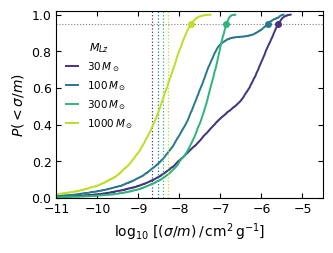

In [7]:
COLS = dict(zip(SCAN, plt.cm.viridis(np.linspace(0.15, 0.9, len(SCAN)))))
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 7.5, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    for m in SCAN:
        x = np.sort(np.log10(SIG[m]))
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=COLS[m], lw=1.4,
                label=rf'${m:g}\,M_\odot$')
        ax.plot([np.log10(np.percentile(SIG[m], 95))], [0.95], 'o', color=COLS[m], ms=4, zorder=5)
        ax.axvline(np.log10(INJ[m]), color=COLS[m], lw=0.9, ls=':')
    ax.axhline(0.95, color='0.5', ls=':', lw=0.8)
    ax.set(xlabel=r'$\log_{10}\,[(\sigma/m)\,/\,{\rm cm^2\,g^{-1}}]$', ylabel=r'$P(<\sigma/m)$',
           xlim=(-11, -4.5), ylim=(0, 1.02))
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(0.0, 0.6), title=r'$M_{Lz}$', title_fontsize=8,
              handlelength=1.2)
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'sidm_mass_scan.png', dpi=300, bbox_inches='tight')
    plt.show()

Cumulative posterior of $\sigma/m$ for each lens mass. Dots mark the 95% upper limits, and dotted vertical lines the injected values ($x_c = 0.02$).

## 5. Comparison with other SIDM probes

The paper's comparison figure places these limits against published SIDM constraints, as a function of the mean relative velocity of the lens halo. The black line is the Fisher forecast for a lens with a negligible core ($x_c = 0.002$, the smallest grid core) at $y = 0.3$: for each grid mass we draw from the Fisher Gaussian restricted to the inference prior (Sec. 2), give each draw a $z_L$ from $P(z_L \mid M_{Lz})$, and take the 95th percentile of $\sigma/m$. It starts at $M_{Lz} = 100\,M_\odot$, the lightest informative inference run, interpolated in $\log M_{Lz}$. Triangles are the inference limits of Sec. 4 at $M_{Lz} = 100$, 300 and $1000\,M_\odot$ (lighter lenses are prior dominated). Each point sits at the median $\langle v\rangle$ of a lens of its mass.

In [8]:
LIT = [  # (label, v_lo, v_hi [km/s], value or (lo, hi) [cm^2/g], kind, colour)
    ('Bullet Cluster', 3500, 4500, 0.7, 'ul', 'tab:brown'),
    ('cluster mergers', 500, 4000, 2.0, 'soft', 'tab:olive'),
    ('cluster halo shapes', 1100, 1500, 1.0, 'soft', 'tab:pink'),
    ('cluster strong lensing', 1300, 1620, 0.13, 'ul', 'tab:red'),
    ('relaxed clusters', 1700, 2100, 0.35, 'ul', 'darkred'),
    ('relaxed groups', 1000, 1300, 1.1, 'ul', 'tab:orange'),
    ('clusters', 1000, 2100, (0.06, 0.28), 'range', 'tab:red'),
    ('groups', 1000, 1300, (0.3, 0.7), 'range', 'tab:orange'),
    ('dwarf/LSB rotation curves', 30, 200, (1.5, 2.5), 'range', 'tab:green'),
    ('too-big-to-fail', 40, 60, (0.5, 50.0), 'range', 'tab:cyan'),
    ('MW dSphs, gravothermal', 20, 60, (20.0, 150.0), 'range', 'tab:purple'),
    ('strong-lens flux ratios', 3, 30, (100.0, 1000.0), 'cond', 'tab:gray'),
]
CITE = {'Bullet Cluster': 'Randall+08', 'cluster mergers': 'Harvey+15, Wittman+18', 'cluster halo shapes': 'Peter+13',
        'cluster strong lensing': 'Andrade+22', 'relaxed clusters': 'Sagunski+21', 'relaxed groups': 'Sagunski+21',
        'clusters': 'Kaplinghat+16, Sagunski+21', 'groups': 'Sagunski+21', 'dwarf/LSB rotation curves': 'Kaplinghat+16',
        'too-big-to-fail': 'Zavala+13, Elbert+15', 'MW dSphs, gravothermal': 'Correa 21',
        'strong-lens flux ratios': 'Gilman+23'}

i0 = 0                                                    # smallest grid core, x_c = 0.002
fis = []
for j, M in enumerate(M_grid):
    if M < 70:
        continue
    w, V = np.linalg.eigh(grid['cov_t'][i0, j, k])
    d = np.array((np.log(M), Y_TRUE, grid['x_c'][i0])) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
    d = d[(d[:, 0] >= LNM_BOX[0]) & (d[:, 0] <= LNM_BOX[1]) & (d[:, 1] >= Y_BOX[0]) & (d[:, 1] <= Y_BOX[1])
          & (d[:, 2] >= XC_BOX[0]) & (d[:, 2] <= XC_BOX[1])][:60000]
    mlz = np.exp(d[:, 0])
    s_m = v_and_sigma_over_m(np.maximum(d[:, 2], 1e-8), mlz, draw_zL(mlz))[1]
    v_m = v_and_sigma_over_m(0.0, float(M), draw_zL(np.full(20000, float(M))))[0]
    fis.append((M, np.median(v_m), np.percentile(s_m, 95)))
fis = np.array(fis)
lm = np.log10(fis[:, 0])
start = [100.0, 10 ** np.interp(2.0, lm, np.log10(fis[:, 1])), 10 ** np.interp(2.0, lm, np.log10(fis[:, 2]))]
fis = np.vstack([start, fis[fis[:, 0] > 100]])
pd.DataFrame(fis, columns=['M_Lz', '<v> [km/s]', 'Fisher sigma/m 95% UL [cm2/g]']).style.format('{:.3g}')

,M_Lz,[km/s],Fisher sigma/m 95% UL [cm2/g]
0,100,3.96,2.76e-06
1,132,4.25,2.57e-06
2,228,4.87,2.24e-06
3,392,5.58,6.99e-08
4,675,6.39,1.95e-08
5,1.16e+03,7.32,1.39e-08
6,2e+03,8.38,3.51e-09


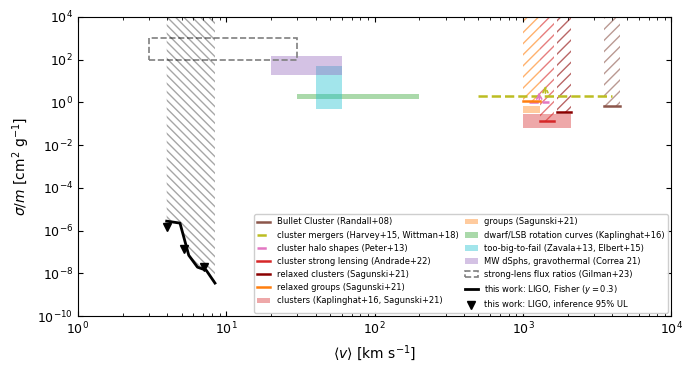

In [9]:
TOP = 1e4
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(7.0, 3.8))
    handles, labels = [], []
    for lab, v0, v1, val, kind, col in LIT:
        if kind in ('ul', 'soft'):          # upper limit (hatched above) or model-dependent limit (dashed)
            ls = '-' if kind == 'ul' else '--'
            ax.plot([v0, v1], [val, val], color=col, lw=1.8, ls=ls)
            if kind == 'ul':
                ax.add_patch(plt.Rectangle((v0, val), v1 - v0, TOP - val, facecolor='none', edgecolor=col, hatch='///',
                                           lw=0, alpha=0.6))
            else:
                ax.annotate('', xy=(np.sqrt(v0 * v1), val * 4), xytext=(np.sqrt(v0 * v1), val),
                            arrowprops=dict(arrowstyle='->', color=col, lw=1.2, ls='--'))
            handles.append(plt.Line2D([], [], color=col, lw=1.8, ls=ls))
        else:                               # measured or preferred range (filled), or conditional (dashed box)
            filled = kind == 'range'
            ax.add_patch(plt.Rectangle((v0, val[0]), v1 - v0, val[1] - val[0], facecolor=col if filled else 'none',
                                       edgecolor='none' if filled else col, alpha=0.4 if filled else 1, ls='--', lw=1.2))
            handles.append(plt.Rectangle((0, 0), 1, 1, facecolor=col if filled else 'none',
                                         edgecolor='none' if filled else col, alpha=0.4 if filled else 1, ls='--', lw=1.2))
        labels.append(f'{lab} ({CITE[lab]})')
    ax.plot(fis[:, 1], fis[:, 2], '-', color='k', lw=2)
    ax.fill_between(fis[:, 1], fis[:, 2], TOP, facecolor='none', edgecolor='k', hatch='\\\\\\\\', lw=0, alpha=0.35)
    handles.append(plt.Line2D([], [], color='k', lw=2)); labels.append(r'this work: LIGO, Fisher ($y=0.3$)')
    pe = np.array([(VEL[m], np.percentile(SIG[m], 95)) for m in [100, 300, 1000]])
    ax.plot(pe[:, 0], pe[:, 1], 'v', color='k', ms=6)
    handles.append(plt.Line2D([], [], marker='v', color='k', ls='none', ms=6))
    labels.append('this work: LIGO, inference 95% UL')
    ax.set(xscale='log', yscale='log', xlim=(1, 1e4), ylim=(1e-10, TOP),
           xlabel=r'$\langle v\rangle$ [km s$^{-1}$]', ylabel=r'$\sigma/m$ [cm$^2$ g$^{-1}$]')
    ax.legend(handles, labels, fontsize=6, loc='lower right', bbox_to_anchor=(1.0, 0.0), ncol=2, frameon=True,
              framealpha=0.95, edgecolor='0.8', handlelength=1.5, columnspacing=0.8, borderaxespad=0.4)
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'sidm_probes.png', dpi=300, bbox_inches='tight')
    plt.show()

Hatched: excluded. Filled: measured or preferred. Dashed: model dependent. Comparing across velocities assumes a velocity-independent cross section.